Testbild ausgewählt: 000838_bmp.rf.9bc49b886c36d94f63456cee28a47224.jpg
--- ANALYSE ERGEBNIS --- 
Military: 1
Logistics: 2
Civilian/Other: 0
Unknown: 0


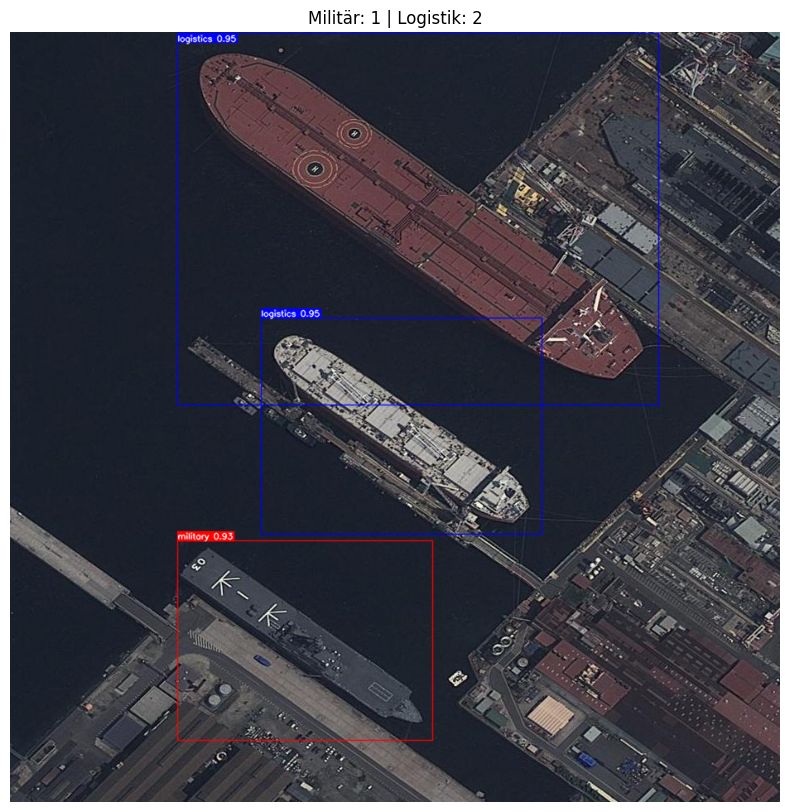

In [30]:
import sys
import os
import cv2
import random
from ultralytics import YOLO
from ultralytics.utils.plotting import Annotator
import matplotlib.pyplot as plt

# Verbindung zu mapping.py herstellen
sys.path.append(os.path.abspath('..'))
from src.mapping import SHIP_MAPPING, CAT_COLORS

# Modell laden und Bildpfad angeben 
model = YOLO('../models/final_weights/v2_3classes_best.pt')
# Pfad zum Bilder-Ordner
image_folder = '../data/processed/ship_data/test/images/'

# Überprüfung und Auflistung der Bilddateien
if os.path.exists(image_folder):
    all_images = [f for f in os.listdir(image_folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
else:
    all_images = []

if len(all_images) > 0:
    # Zufällige Auswahl eines Testbildes
    random_image = random.choice(all_images)
    test_img_path = os.path.join(image_folder, random_image)
    print(f"Testbild ausgewählt: {random_image}")
else:
    raise FileNotFoundError(f"Das Verzeichnis {image_folder} wurde nicht gefunden oder enthält keine Bilder.")

# Die KI rechnen lassen (Inference) 
results = model.predict(test_img_path, conf=0.6, iou=0.5, verbose=False)

# Das Ergebnis-Bild vorbereiten 
img = cv2.imread(test_img_path)
annotator = Annotator(img, line_width=1, font_size=10) 

# Liste um die Schiffe zu zählen
stats = {cat: 0 for cat in SHIP_MAPPING.keys()}
stats['Unknown'] = 0

# Die Ergebnisse der KI sortieren und die Schiffe zählen
for r in results:
    for box in r.boxes:
        cls_id = int(box.cls[0])
        label = model.names[cls_id]
        coords = box.xyxy[0]
        
        conf_val = float(box.conf[0]) 
        
        # Die neue Logik für Version 2 (erkennt Hauptkategorien UND Untertypen)
        category = "Unknown"
        label_str = str(label).lower()

        for cat, classes in SHIP_MAPPING.items():
            # Check 1: Ist das Label direkt die Kategorie (z.B. 'military')?
            # Check 2: Ist es 'civilian/other' (Sonderfall wegen des Schrägstrichs)?
            # Check 3: Ist es einer der alten Untertypen (z.B. 'Destroyer')?
            if label_str == cat.lower() or \
               (label_str == "civilian" and cat == "Civilian/Other") or \
               label in classes:
                category = cat
                break
        
        stats[category] += 1
        
        
        current_color = CAT_COLORS.get(category, (128, 128, 128))
        annotator.box_label(coords, label=f"{label} {conf_val:.2f}", color=current_color, txt_color=(255, 255, 255))



# Alles anzeigen 
print(f"--- ANALYSE ERGEBNIS --- ")
for cat, count in stats.items():
    print(f"{cat}: {count}")

final_img = annotator.result()
img_rgb = cv2.cvtColor(final_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(img_rgb)
plt.axis('off')
plt.title(f"Militär: {stats['Military']} | Logistik: {stats['Logistics']}")
plt.show()